<a href="https://colab.research.google.com/github/michaelseth5/-Monte-Carlo-Simulation-for-College-Football-Team-Rankings/blob/main/Aditi_Kamath_Splitting_Data_(Part_2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import json
import pandas as pd
import json
import re
from collections import defaultdict

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
with open("train_separate_questions.json", "r") as f:
    train_data = json.load(f)

with open("test.json", "r") as f:
    test_data = json.load(f)

category_descriptions = pd.read_csv("category_descriptions.csv")

print("Files loaded successfully.")

Files loaded successfully.


In [ ]:
print("train_data type:", type(train_data))
print("test_data type:", type(test_data))

if isinstance(test_data, list):
    print("Number of test records:", len(test_data))
    print("First record type:", type(test_data[0]))

    if isinstance(test_data[0], dict):
        print("First record keys:", test_data[0].keys())

train_data type: <class 'dict'>
test_data type: <class 'dict'>


In [ ]:
print("Train contracts:", len(train_data["data"]))
print("Test contracts:", len(test_data["data"]))
print("Total contracts:", len(train_data["data"]) + len(test_data["data"]))

print("\nCategory descriptions shape:")
print(category_descriptions.shape)

Train contracts: 408
Test contracts: 102
Total contracts: 510

Category descriptions shape:
(41, 4)


In [ ]:
display(category_descriptions)

,Category (incl. context and answer),Description,Answer Format,Group
0,Category: Document Name,Description: The name of the contract,Answer Format: Contract Name,Group: -
1,Category: Parties,Description: The two or more parties who signe...,Answer Format: Entity or individual names,Group: -
2,Category: Agreement Date,Description: The date of the contract,Answer Format: Date (mm/dd/yyyy),Group: 1
3,Category: Effective Date,Description: The date when the contract is eff...,Answer Format: Date (mm/dd/yyyy),Group: 1
4,Category: Expiration Date,Description: On what date will the contract's ...,Answer Format: Date (mm/dd/yyyy) / Perpetual,Group: 1
5,Category: Renewal Term,Description: What is the renewal term after th...,Answer Format: [Successive] number of years/mo...,Group: 1
6,Category: Notice Period to Terminate Renewal,Description: What is the notice period require...,Answer Format: Number of days/months/year(s),Group: 1
7,Category: Governing Law,Description: Which state/country's law governs...,Answer Format: Name of a US State / non-US Pro...,Group: -
8,Category: Most Favored Nation,Description: Is there a clause that if a third...,Answer Format: Yes/No,Group: -
9,Category: Non-Compete,Description: Is there a restriction on the abi...,Answer Format: Yes/No,Group: 2


In [ ]:
print(category_descriptions.columns.tolist())

['Category (incl. context and answer)', 'Description', 'Answer Format', 'Group']


In [ ]:
contract = train_data["data"][0]
paragraph = contract["paragraphs"][0]

print("Contract title:")
print(contract["title"])

print("\nContract keys:")
print(contract.keys())

print("\nParagraph keys:")
print(paragraph.keys())

print("\nNumber of QAs:")
print(len(paragraph["qas"]))

Contract title:
LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT

Contract keys:
dict_keys(['title', 'paragraphs'])

Paragraph keys:
dict_keys(['qas', 'context'])

Number of QAs:
68


In [ ]:
for qa in paragraph["qas"][:3]:

    print("ID:", qa["id"])
    print("Question:", qa["question"])
    print("Is impossible:", qa["is_impossible"])

    if qa["answers"]:
        print("Answer:", qa["answers"][0]["text"])
        print("Answer start:", qa["answers"][0]["answer_start"])
    else:
        print("Answer: NONE")

    print("-" * 80)

ID: LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT__Document Name_0
Question: Highlight the parts (if any) of this contract related to "Document Name" that should be reviewed by a lawyer. Details: The name of the contract
Is impossible: False
Answer: DISTRIBUTOR AGREEMENT
Answer start: 44
--------------------------------------------------------------------------------
ID: LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT__Parties_0
Question: Highlight the parts (if any) of this contract related to "Parties" that should be reviewed by a lawyer. Details: The two or more parties who signed the contract
Is impossible: False
Answer: Distributor
Answer start: 244
--------------------------------------------------------------------------------
ID: LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT__Parties_1
Question: Highlight the parts (if any) of this contract related to "Parties" that should be reviewed by a lawyer. Details: The two or more parties who signed the contract
Is impos

In [ ]:
def get_category(qa):
    category = qa["id"].split("__")[-1]

    # Remove ending _0, _1, _2, _15, etc.
    category = re.sub(r'_\d+$', '', category)

    return category

print(get_category({
    "id": "SomeContract__Audit Rights_14"
}))

Audit Rights


In [ ]:
unique_categories = set()

for dataset in [train_data, test_data]:
    for contract in dataset["data"]:
        for paragraph in contract["paragraphs"]:
            for qa in paragraph["qas"]:
                unique_categories.add(get_category(qa))

unique_categories = sorted(unique_categories)

print("Number of unique categories:", len(unique_categories))

for category in unique_categories:
    print(category)

Number of unique categories: 41
Affiliate License-Licensee
Affiliate License-Licensor
Agreement Date
Anti-Assignment
Audit Rights
Cap On Liability
Change Of Control
Competitive Restriction Exception
Covenant Not To Sue
Document Name
Effective Date
Exclusivity
Expiration Date
Governing Law
Insurance
Ip Ownership Assignment
Irrevocable Or Perpetual License
Joint Ip Ownership
License Grant
Liquidated Damages
Minimum Commitment
Most Favored Nation
No-Solicit Of Customers
No-Solicit Of Employees
Non-Compete
Non-Disparagement
Non-Transferable License
Notice Period To Terminate Renewal
Parties
Post-Termination Services
Price Restrictions
Renewal Term
Revenue/Profit Sharing
Rofr/Rofo/Rofn
Source Code Escrow
Termination For Convenience
Third Party Beneficiary
Uncapped Liability
Unlimited/All-You-Can-Eat-License
Volume Restriction
Warranty Duration


In [ ]:
def count_positive_contracts(data):

    counts = defaultdict(int)

    for contract in data["data"]:

        categories_in_contract = set()

        for paragraph in contract["paragraphs"]:
            for qa in paragraph["qas"]:

                if len(qa["answers"]) > 0:
                    category = get_category(qa)
                    categories_in_contract.add(category)

        # Count each category at most once per contract
        for category in categories_in_contract:
            counts[category] += 1

    return counts


train_counts = count_positive_contracts(train_data)
test_counts = count_positive_contracts(test_data)

In [ ]:
rows = []

for category in unique_categories:

    train_count = train_counts.get(category, 0)
    test_count = test_counts.get(category, 0)

    rows.append({
        "Category": category,
        "Train Contracts": train_count,
        "Test Contracts": test_count,
        "Total Contracts": train_count + test_count
    })


category_df = pd.DataFrame(rows)

category_df = category_df.sort_values(
    "Train Contracts",
    ascending=False
).reset_index(drop=True)

display(category_df)

,Category,Train Contracts,Test Contracts,Total Contracts
0,Document Name,408,102,510
1,Parties,407,102,509
2,Agreement Date,377,93,470
3,Governing Law,354,83,437
4,Expiration Date,335,78,413
5,Effective Date,320,70,390
6,Anti-Assignment,302,72,374
7,Cap On Liability,231,44,275
8,License Grant,205,50,255
9,Audit Rights,176,38,214


In [ ]:
num_train = len(train_data["data"])
num_test = len(test_data["data"])
num_total = num_train + num_test

category_df["Train %"] = (
    category_df["Train Contracts"] / num_train * 100
).round(2)

category_df["Test %"] = (
    category_df["Test Contracts"] / num_test * 100
).round(2)

category_df["Total %"] = (
    category_df["Total Contracts"] / num_total * 100
).round(2)

display(category_df)

,Category,Train Contracts,Test Contracts,Total Contracts,Train %,Test %,Total %
0,Document Name,408,102,510,100.00,100.00,100.00
1,Parties,407,102,509,99.75,100.00,99.80
2,Agreement Date,377,93,470,92.40,91.18,92.16
3,Governing Law,354,83,437,86.76,81.37,85.69
4,Expiration Date,335,78,413,82.11,76.47,80.98
5,Effective Date,320,70,390,78.43,68.63,76.47
6,Anti-Assignment,302,72,374,74.02,70.59,73.33
7,Cap On Liability,231,44,275,56.62,43.14,53.92
8,License Grant,205,50,255,50.25,49.02,50.00
9,Audit Rights,176,38,214,43.14,37.25,41.96


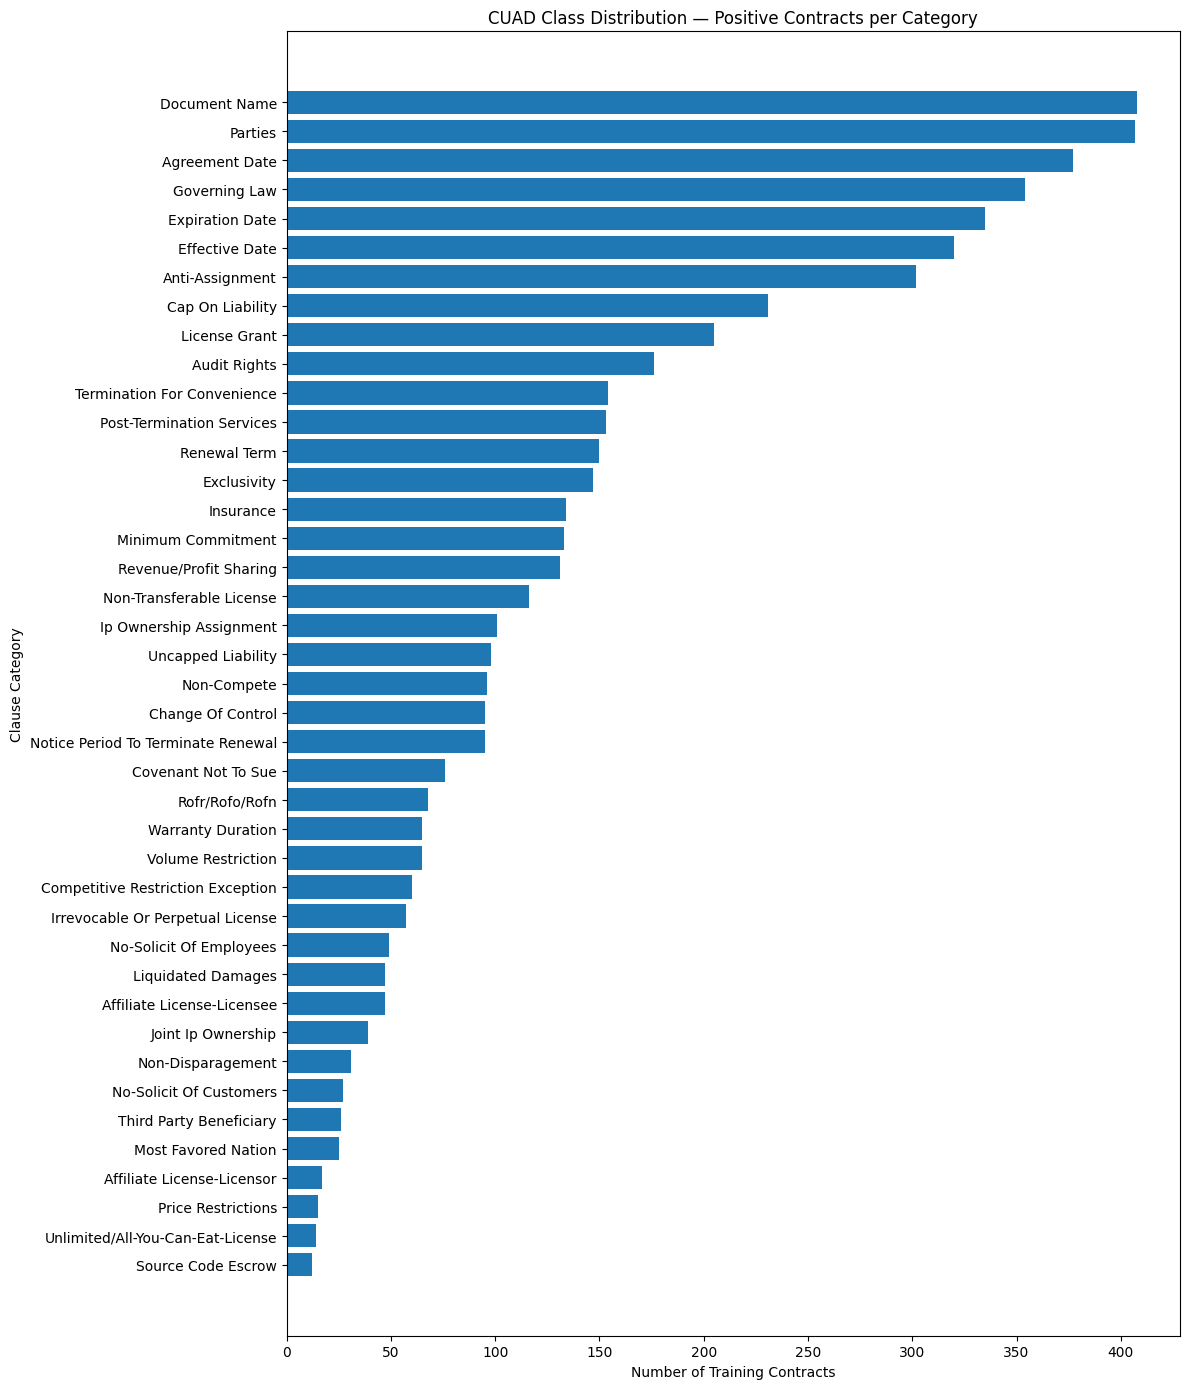

In [ ]:
plot_df = category_df.sort_values(
    "Train Contracts",
    ascending=True
)

plt.figure(figsize=(12, 14))

plt.barh(
    plot_df["Category"],
    plot_df["Train Contracts"]
)

plt.xlabel("Number of Training Contracts")
plt.ylabel("Clause Category")
plt.title("CUAD Class Distribution — Positive Contracts per Category")

plt.tight_layout()
plt.show()

In [ ]:
priority_categories = [
    "Cap On Liability",
    "Uncapped Liability",
    "Termination For Convenience",
    "Governing Law",
    "Renewal Term",
    "Ip Ownership Assignment",
    "Change Of Control",
    "Non-Compete",
    "Audit Rights",
    "Most Favored Nation"
]

In [ ]:
for category in priority_categories:

    if category in unique_categories:
        print("FOUND:  ", category)
    else:
        print("MISSING:", category)

FOUND:   Cap On Liability
FOUND:   Uncapped Liability
FOUND:   Termination For Convenience
FOUND:   Governing Law
FOUND:   Renewal Term
FOUND:   Ip Ownership Assignment
FOUND:   Change Of Control
FOUND:   Non-Compete
FOUND:   Audit Rights
FOUND:   Most Favored Nation


In [ ]:
priority_df = category_df[
    category_df["Category"].isin(priority_categories)
].copy()

priority_df = priority_df.sort_values(
    "Train Contracts",
    ascending=False
).reset_index(drop=True)

display(priority_df)

,Category,Train Contracts,Test Contracts,Total Contracts,Train %,Test %,Total %
0,Governing Law,354,83,437,86.76,81.37,85.69
1,Cap On Liability,231,44,275,56.62,43.14,53.92
2,Audit Rights,176,38,214,43.14,37.25,41.96
3,Termination For Convenience,154,29,183,37.75,28.43,35.88
4,Renewal Term,150,26,176,36.76,25.49,34.51
5,Ip Ownership Assignment,101,23,124,24.75,22.55,24.31
6,Uncapped Liability,98,13,111,24.02,12.75,21.76
7,Non-Compete,96,23,119,23.53,22.55,23.33
8,Change Of Control,95,26,121,23.28,25.49,23.73
9,Most Favored Nation,25,3,28,6.13,2.94,5.49


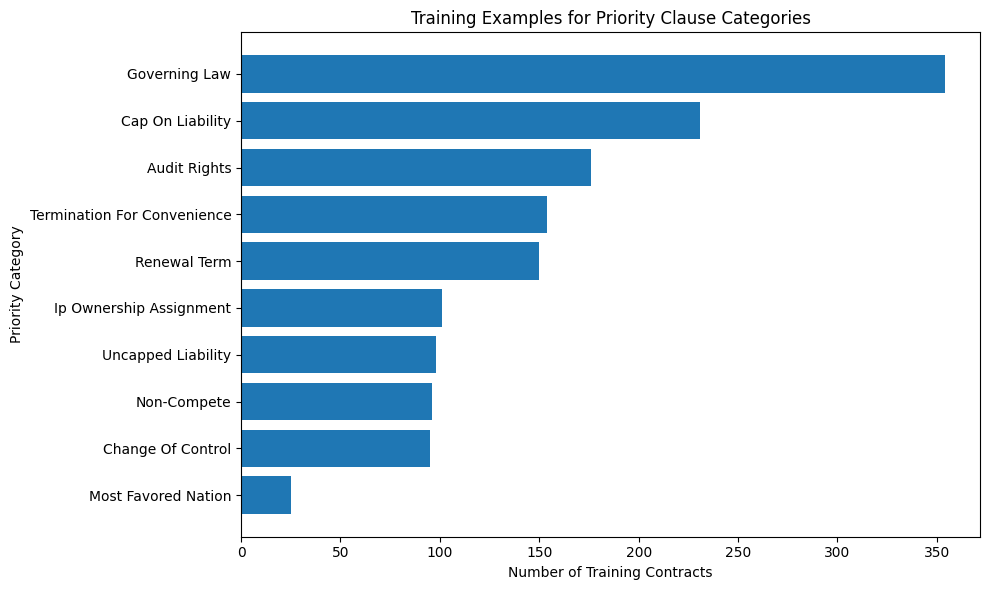

In [ ]:
priority_plot = priority_df.sort_values(
    "Train Contracts",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    priority_plot["Category"],
    priority_plot["Train Contracts"]
)

plt.xlabel("Number of Training Contracts")
plt.ylabel("Priority Category")
plt.title("Training Examples for Priority Clause Categories")

plt.tight_layout()
plt.show()

In [ ]:
imbalance_df = category_df.copy()

imbalance_df["Positive"] = imbalance_df["Train Contracts"]

imbalance_df["Negative"] = (
    num_train - imbalance_df["Train Contracts"]
)

imbalance_df["Positive:Negative Ratio"] = (
    imbalance_df["Positive"] /
    imbalance_df["Negative"].replace(0, 1)
).round(3)

display(
    imbalance_df[
        [
            "Category",
            "Positive",
            "Negative",
            "Positive:Negative Ratio"
        ]
    ]
)

,Category,Positive,Negative,Positive:Negative Ratio
0,Document Name,408,0,408.000
1,Parties,407,1,407.000
2,Agreement Date,377,31,12.161
3,Governing Law,354,54,6.556
4,Expiration Date,335,73,4.589
5,Effective Date,320,88,3.636
6,Anti-Assignment,302,106,2.849
7,Cap On Liability,231,177,1.305
8,License Grant,205,203,1.010
9,Audit Rights,176,232,0.759


In [ ]:
rarest_categories = category_df.sort_values(
    "Train Contracts",
    ascending=True
)

display(
    rarest_categories[
        ["Category", "Train Contracts", "Train %"]
    ]
)

,Category,Train Contracts,Train %
40,Source Code Escrow,12,2.94
39,Unlimited/All-You-Can-Eat-License,14,3.43
38,Price Restrictions,15,3.68
37,Affiliate License-Licensor,17,4.17
36,Most Favored Nation,25,6.13
35,Third Party Beneficiary,26,6.37
34,No-Solicit Of Customers,27,6.62
33,Non-Disparagement,31,7.60
32,Joint Ip Ownership,39,9.56
30,Affiliate License-Licensee,47,11.52


In [ ]:
contract_lengths = []

for contract in train_data["data"]:

    full_text = " ".join(
        paragraph["context"]
        for paragraph in contract["paragraphs"]
    )

    contract_lengths.append({
        "Contract": contract["title"],
        "Characters": len(full_text),
        "Words": len(full_text.split())
    })


length_df = pd.DataFrame(contract_lengths)

display(length_df.head())

,Contract,Characters,Words
0,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,54290,5998
1,"WHITESMOKE,INC_11_08_2011-EX-10.26-PROMOTION A...",70383,11313
2,NELNETINC_04_08_2020-EX-1-JOINT FILING AGREEMENT,1081,170
3,ADAMSGOLFINC_03_21_2005-EX-10.17-ENDORSEMENT A...,24632,3770
4,"KIROMICBIOPHARMA,INC_05_11_2020-EX-10.23-CONSU...",18403,2766


In [ ]:
display(
    length_df[["Characters", "Words"]].describe()
)

,Characters,Words
count,408.000000,408.000000
mean,53991.710784,8045.085784
std,55985.180326,8300.180187
min,1081.000000,170.000000
25%,16569.750000,2536.750000
50%,35960.500000,5357.500000
75%,68439.750000,10398.250000
max,338211.000000,45650.000000


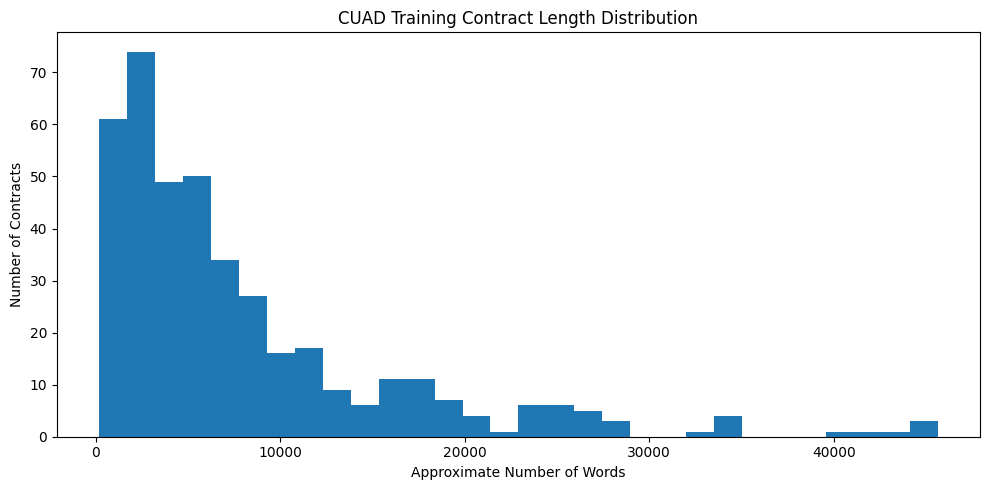

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(
    length_df["Words"],
    bins=30
)

plt.xlabel("Approximate Number of Words")
plt.ylabel("Number of Contracts")
plt.title("CUAD Training Contract Length Distribution")

plt.tight_layout()
plt.show()

In [ ]:
def count_answer_spans(data):

    counts = defaultdict(int)

    for contract in data["data"]:
        for paragraph in contract["paragraphs"]:
            for qa in paragraph["qas"]:

                category = get_category(qa)

                counts[category] += len(qa["answers"])

    return counts


train_span_counts = count_answer_spans(train_data)

In [ ]:
category_df["Train Answer Spans"] = (
    category_df["Category"]
    .map(train_span_counts)
    .fillna(0)
    .astype(int)
)

display(
    category_df[
        [
            "Category",
            "Train Contracts",
            "Train Answer Spans",
            "Train %"
        ]
    ]
)

,Category,Train Contracts,Train Answer Spans,Train %
0,Document Name,408,419,100.00
1,Parties,407,2011,99.75
2,Agreement Date,377,383,92.40
3,Governing Law,354,374,86.76
4,Expiration Date,335,384,82.11
5,Effective Date,320,363,78.43
6,Anti-Assignment,302,517,74.02
7,Cap On Liability,231,554,56.62
8,License Grant,205,642,50.25
9,Audit Rights,176,538,43.14


In [ ]:
print("=== EDA SANITY CHECK ===")

print("Train contracts:", len(train_data["data"]))
print("Test contracts:", len(test_data["data"]))
print("Total contracts:",
      len(train_data["data"]) + len(test_data["data"]))

print("Unique categories:", len(unique_categories))

print("\nMost common category:")
display(category_df.head(1))

print("\nRarest category:")
display(category_df.tail(1))

print("\nPriority categories:")
display(priority_df)

=== EDA SANITY CHECK ===
Train contracts: 408
Test contracts: 102
Total contracts: 510
Unique categories: 41

Most common category:


,Category,Train Contracts,Test Contracts,Total Contracts,Train %,Test %,Total %,Train Answer Spans
0,Document Name,408,102,510,100.0,100.0,100.0,419



Rarest category:


,Category,Train Contracts,Test Contracts,Total Contracts,Train %,Test %,Total %,Train Answer Spans
40,Source Code Escrow,12,1,13,2.94,0.98,2.55,61



Priority categories:


,Category,Train Contracts,Test Contracts,Total Contracts,Train %,Test %,Total %
0,Governing Law,354,83,437,86.76,81.37,85.69
1,Cap On Liability,231,44,275,56.62,43.14,53.92
2,Audit Rights,176,38,214,43.14,37.25,41.96
3,Termination For Convenience,154,29,183,37.75,28.43,35.88
4,Renewal Term,150,26,176,36.76,25.49,34.51
5,Ip Ownership Assignment,101,23,124,24.75,22.55,24.31
6,Uncapped Liability,98,13,111,24.02,12.75,21.76
7,Non-Compete,96,23,119,23.53,22.55,23.33
8,Change Of Control,95,26,121,23.28,25.49,23.73
9,Most Favored Nation,25,3,28,6.13,2.94,5.49


# Chunk-Based Multi-Label Data Preparation

This section converts each contract into overlapping 512-token chunks and maps
CUAD's annotated clause spans to the appropriate chunks. Each resulting chunk
will retain its contract ID, clause labels, and supporting evidence.

In [ ]:
!pip install -q transformers

In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "distilroberta-base",
    use_fast=True
)

print("Tokenizer loaded successfully.")
print("Maximum model length:", tokenizer.model_max_length)

Tokenizer loaded successfully.
Maximum model length: 512


In [ ]:
def extract_annotations(contract):
    annotations = []

    for paragraph_index, paragraph in enumerate(contract["paragraphs"]):
        for qa in paragraph["qas"]:
            category = get_category(qa)

            for answer in qa["answers"]:
                start = answer["answer_start"]
                text = answer["text"]

                annotations.append({
                    "paragraph_index": paragraph_index,
                    "category": category,
                    "answer_text": text,
                    "answer_start": start,
                    "answer_end": start + len(text)
                })

    return annotations

Tests turning the annotations out of the nested JSON and turning them into a simpler list on one contract

In [ ]:
sample_contract = train_data["data"][0]
sample_annotations = extract_annotations(sample_contract)

print("Contract:", sample_contract["title"])
print("Number of annotated spans:", len(sample_annotations))

sample_annotations[:3]

Contract: LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT
Number of annotated spans: 46


[{'paragraph_index': 0,
  'category': 'Document Name',
  'answer_text': 'DISTRIBUTOR AGREEMENT',
  'answer_start': 44,
  'answer_end': 65},
 {'paragraph_index': 0,
  'category': 'Parties',
  'answer_text': 'Distributor',
  'answer_start': 244,
  'answer_end': 255},
 {'paragraph_index': 0,
  'category': 'Parties',
  'answer_text': 'Electric City of Illinois L.L.C.',
  'answer_start': 49574,
  'answer_end': 49606}]

Verify the annotation positions

Now the 512-token chunks with 64 token overlap need to be created

In [ ]:
def create_chunks(context, max_length=512, overlap=64):
    # Reserve 2 positions for RoBERTa special tokens
    content_length = max_length - 2
    step = content_length - overlap

    encoded = tokenizer(
        context,
        add_special_tokens=False,
        return_offsets_mapping=True,
        truncation=False
    )

    token_ids = encoded["input_ids"]
    offsets = encoded["offset_mapping"]
    chunks = []

    for chunk_id, token_start in enumerate(
        range(0, len(token_ids), step)
    ):
        token_end = min(token_start + content_length, len(token_ids))
        window_offsets = offsets[token_start:token_end]

        chunk_start = window_offsets[0][0]
        chunk_end = window_offsets[-1][1]

        chunks.append({
            "chunk_id": chunk_id,
            "chunk_start": chunk_start,
            "chunk_end": chunk_end,
            "chunk_text": context[chunk_start:chunk_end],
            "token_count": (token_end - token_start) + 2,
            "labels": [],
            "evidence": []
        })

        if token_end == len(token_ids):
            break

    return chunks

In [ ]:
sample_context = sample_contract["paragraphs"][0]["context"]
sample_chunks = create_chunks(sample_context)

print("Contract characters:", len(sample_context))
print("Chunks:", len(sample_chunks))
print("First range:",
      sample_chunks[0]["chunk_start"],
      sample_chunks[0]["chunk_end"])
print("Last range:",
      sample_chunks[-1]["chunk_start"],
      sample_chunks[-1]["chunk_end"])
print("Maximum tokens:",
      max(chunk["token_count"] for chunk in sample_chunks))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (23248 > 512). Running this sequence through the model will result in indexing errors


Contract characters: 54290
Chunks: 52
First range: 0 1820
Last range: 53110 54290
Maximum tokens: 512


Test the function, which should break the contract into inputs of no more than 512 tokens and repeats about 64 tokens between neighboring chunks. It also creates empty labels and evidence fields for the next step.

In [ ]:
sample_context = sample_contract["paragraphs"][0]["context"]
sample_chunks = create_chunks(sample_context)

print("Contract characters:", len(sample_context))
print("Number of chunks:", len(sample_chunks))
print("Maximum token count:", max(
    chunk["token_count"] for chunk in sample_chunks
))

Contract characters: 54290
Number of chunks: 52
Maximum token count: 512


Inspects the first chunk

In [ ]:
first_chunk = sample_chunks[0]

print("Chunk ID:", first_chunk["chunk_id"])
print("Character range:",
      first_chunk["chunk_start"],
      "to",
      first_chunk["chunk_end"])
print("Token count:", first_chunk["token_count"])
print("\nChunk preview:\n")
print(first_chunk["chunk_text"][:1000])

Chunk ID: 0
Character range: 0 to 1820
Token count: 512

Chunk preview:

EXHIBIT 10.6

                              DISTRIBUTOR AGREEMENT

         THIS  DISTRIBUTOR  AGREEMENT (the  "Agreement")  is made by and between Electric City Corp.,  a Delaware  corporation  ("Company")  and Electric City of Illinois LLC ("Distributor") this 7th day of September, 1999.

                                    RECITALS

         A. The  Company's  Business.  The Company is  presently  engaged in the business  of selling an energy  efficiency  device,  which is  referred to as an "Energy  Saver"  which may be improved  or  otherwise  changed  from its present composition (the "Products").  The Company may engage in the business of selling other  products  or  other  devices  other  than  the  Products,  which  will be considered  Products if Distributor  exercises its options pursuant to Section 7 hereof.

         B. Representations.  As an inducement to the Company to enter into this Agreement,  t

Inspects the start and end of the first 2 chunks

In [ ]:
for chunk in sample_chunks[:2]:
    print("=" * 80)
    print("Chunk ID:", chunk["chunk_id"])
    print("Range:", chunk["chunk_start"], "-", chunk["chunk_end"])
    print("Token count:", chunk["token_count"])
    print("Beginning:", repr(chunk["chunk_text"][:100]))
    print("End:", repr(chunk["chunk_text"][-100:]))

Chunk ID: 0
Range: 0 - 1820
Token count: 512
Beginning: 'EXHIBIT 10.6\n\n                              DISTRIBUTOR AGREEMENT\n\n         THIS  DISTRIBUTOR  AGREE'
End: 'government housing authorities and other government agencies and facilities (the "Market").\n\n       '
Chunk ID: 1
Range: 1533 - 2811
Token count: 512
Beginning: 'the State of  Illinois,  including  but not limited to public  and  private  entities,  institutions'
End: '                      the Products may have sites,  locations or operations                         '


Checks the size

In [ ]:
oversized_chunks = [
    chunk for chunk in sample_chunks
    if chunk["token_count"] > 512
]

print("Oversized chunks:", len(oversized_chunks))

Oversized chunks: 0


Now need to add annotations to chunks

In [ ]:
def label_chunks(chunks, annotations):
    unassigned = []

    for annotation in annotations:
        answer_start = annotation["answer_start"]
        answer_end = annotation["answer_end"]
        category = annotation["category"]

        fully_contained_chunks = []
        overlapping_chunks = []

        for chunk in chunks:
            chunk_start = chunk["chunk_start"]
            chunk_end = chunk["chunk_end"]

            # Annotation is completely inside the chunk
            if answer_start >= chunk_start and answer_end <= chunk_end:
                fully_contained_chunks.append(chunk)

            # Number of characters shared by annotation and chunk
            overlap = max(
                0,
                min(answer_end, chunk_end)
                - max(answer_start, chunk_start)
            )

            if overlap > 0:
                overlapping_chunks.append((overlap, chunk))

        # Prefer chunks containing the complete annotation
        if fully_contained_chunks:
            target_chunks = fully_contained_chunks
            assignment_type = "fully_contained"

        # Otherwise use the chunk with the greatest overlap
        elif overlapping_chunks:
            best_overlap, best_chunk = max(
                overlapping_chunks,
                key=lambda item: item[0]
            )
            target_chunks = [best_chunk]
            assignment_type = "maximum_overlap"

        else:
            unassigned.append(annotation)
            continue

        for chunk in target_chunks:
            if category not in chunk["labels"]:
                chunk["labels"].append(category)

            chunk["evidence"].append({
                **annotation,
                "assignment_type": assignment_type
            })

    return chunks, unassigned

Runs the above on a sample contract

In [ ]:
labeled_chunks, unassigned_annotations = label_chunks(
    sample_chunks,
    sample_annotations
)

print("Total chunks:", len(labeled_chunks))
print(
    "Labeled chunks:",
    sum(len(chunk["labels"]) > 0 for chunk in labeled_chunks)
)
print(
    "Unlabeled chunks:",
    sum(len(chunk["labels"]) == 0 for chunk in labeled_chunks)
)
print("Unassigned annotations:", len(unassigned_annotations))

Total chunks: 52
Labeled chunks: 28
Unlabeled chunks: 24
Unassigned annotations: 0


Now, process all contracts

In [ ]:
def process_contracts(contracts, source):
    rows = []
    unassigned_records = []

    for contract_index, contract in enumerate(contracts):
        contract_id = contract.get(
            "title",
            f"{source}_contract_{contract_index}"
        )

        context = contract["paragraphs"][0]["context"]
        annotations = extract_annotations(contract)

        chunks = create_chunks(context)
        labeled_chunks, unassigned = label_chunks(
            chunks,
            annotations
        )

        for chunk in labeled_chunks:
            rows.append({
                "contract_id": contract_id,
                "source": source,
                "chunk_id": chunk["chunk_id"],
                "chunk_start": chunk["chunk_start"],
                "chunk_end": chunk["chunk_end"],
                "chunk_text": chunk["chunk_text"],
                "token_count": chunk["token_count"],
                "labels": chunk["labels"],
                "evidence": chunk["evidence"]
            })

        for annotation in unassigned:
            unassigned_records.append({
                "contract_id": contract_id,
                **annotation
            })

    return rows, unassigned_records

In [ ]:
train_rows, train_unassigned = process_contracts(
    train_data["data"],
    source="original_train"
)

test_rows, test_unassigned = process_contracts(
    test_data["data"],
    source="original_test"
)

In [ ]:
all_rows = train_rows + test_rows
chunked_df = pd.DataFrame(all_rows)

In [ ]:
print("Total contracts:", chunked_df["contract_id"].nunique())
print(
    chunked_df.groupby("source")["contract_id"]
    .nunique()
)
print("Total chunks:", len(chunked_df))
print("Maximum tokens:", chunked_df["token_count"].max())
print("Train unassigned:", len(train_unassigned))
print("Test unassigned:", len(test_unassigned))

Total contracts: 510
source
original_test     102
original_train    408
Name: contract_id, dtype: int64
Total chunks: 14724
Maximum tokens: 512
Train unassigned: 0
Test unassigned: 0


In [ ]:
chunked_df.to_json(
    "cuad_all_510_chunked_multilabel.jsonl",
    orient="records",
    lines=True
)

print("Combined 510-contract dataset saved.")

Combined 510-contract dataset saved.


In [ ]:
print(type(test_data))

if isinstance(test_data, dict):
    test_contracts = test_data["data"]
else:
    test_contracts = test_data

print("Test contracts:", len(test_contracts))
print("First contract keys:", test_contracts[0].keys())

<class 'dict'>
Test contracts: 102
First contract keys: dict_keys(['title', 'paragraphs'])


Process the training data - test on 5 contracts first

Check the label distribution

In [ ]:
label_counts = (
    chunked_df.explode("labels")["labels"]
    .dropna()
    .value_counts()
)

display(label_counts)

,count
labels,
Parties,657
License Grant,585
Document Name,532
Anti-Assignment,519
Cap On Liability,509
Agreement Date,490
Governing Law,478
Expiration Date,470
Effective Date,448


Check how many chunks have no clause label

In [ ]:
chunked_df["has_label"] = chunked_df["labels"].apply(
    lambda labels: len(labels) > 0
)

print(chunked_df["has_label"].value_counts())

has_label
False    9168
True     5556
Name: count, dtype: int64


Save the result

In [ ]:
chunked_df.to_json(
    "cuad_chunked_multilabel.jsonl",
    orient="records",
    lines=True
)

Download the file

In [ ]:
from google.colab import files

files.download("cuad_chunked_multilabel.jsonl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Checking the json file

In [ ]:
chunked_df = pd.read_json(
    "cuad_chunked_multilabel.jsonl",
    lines=True
)

print("Rows:", len(chunked_df))
print("Contracts:", chunked_df["contract_id"].nunique())
print("Maximum tokens:", chunked_df["token_count"].max())
print("Missing contract IDs:", chunked_df["contract_id"].isna().sum())
print("Missing text:", chunked_df["chunk_text"].isna().sum())
print(
    "Labeled chunks:",
    chunked_df["labels"].apply(lambda x: len(x) > 0).sum()
)

Rows: 14724
Contracts: 510
Maximum tokens: 512
Missing contract IDs: 0
Missing text: 0
Labeled chunks: 5556


In [ ]:
print("Globally unassigned annotations:", len(train_unassigned))

Globally unassigned annotations: 0


In [ ]:
# Load Yutika's combined 510-contract chunked dataset
chunked_df = pd.read_json("cuad_all_510_chunked_multilabel.jsonl", lines=True)

print("Total chunks:", len(chunked_df))
print("Total contracts:", chunked_df["contract_id"].nunique())

# Sanity check: contract_id should be unique per contract, no collisions across train/test sources
dupe_check = chunked_df.groupby("contract_id")["source"].nunique()
print("Contract IDs spanning multiple sources (should be 0):", (dupe_check > 1).sum())

Total chunks: 14724
Total contracts: 510
Contract IDs spanning multiple sources (should be 0): 0


In [ ]:
# Get unique contract IDs and shuffle with a fixed seed for reproducibility
contract_ids = chunked_df["contract_id"].unique()
rng = np.random.default_rng(42)
rng.shuffle(contract_ids)

n = len(contract_ids)
n_train = int(n * 0.8)
n_val = int(n * 0.1)

train_ids = contract_ids[:n_train]
val_ids = contract_ids[n_train:n_train + n_val]
test_ids = contract_ids[n_train + n_val:]

print("Train contracts:", len(train_ids))
print("Val contracts:", len(val_ids))
print("Test contracts:", len(test_ids))

Train contracts: 408
Val contracts: 51
Test contracts: 51


In [ ]:
# Split the chunk-level dataframe by contract_id membership
train_df = chunked_df[chunked_df["contract_id"].isin(train_ids)].reset_index(drop=True)
val_df = chunked_df[chunked_df["contract_id"].isin(val_ids)].reset_index(drop=True)
test_df = chunked_df[chunked_df["contract_id"].isin(test_ids)].reset_index(drop=True)

print("Train chunks:", len(train_df), "| contracts:", train_df["contract_id"].nunique())
print("Val chunks:", len(val_df), "| contracts:", val_df["contract_id"].nunique())
print("Test chunks:", len(test_df), "| contracts:", test_df["contract_id"].nunique())

Train chunks: 11500 | contracts: 408
Val chunks: 1998 | contracts: 51
Test chunks: 1226 | contracts: 51


In [ ]:
# Leakage check — no contract_id should appear in more than one split
train_set, val_set, test_set = set(train_ids), set(val_ids), set(test_ids)
print("Train/Val overlap:", len(train_set & val_set))
print("Train/Test overlap:", len(train_set & test_set))
print("Val/Test overlap:", len(val_set & test_set))

Train/Val overlap: 0
Train/Test overlap: 0
Val/Test overlap: 0


In [ ]:
# Check label coverage across splits — flag any priority category missing from a split
priority_categories = [
    "Limitation Of Liability", "Cap On Liability", "Uncapped Liability",
    "Indemnification", "Termination For Convenience", "Governing Law",
    "Most Favored Nation", "Ip Ownership Assignment", "Change Of Control",
    "Non-Compete", "Audit Rights"
]

for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    present = set(df.explode("labels")["labels"].dropna().unique())
    missing = [c for c in priority_categories if c not in present]
    print(f"{name}: missing priority categories -> {missing}")

train: missing priority categories -> ['Limitation Of Liability', 'Indemnification']
val: missing priority categories -> ['Limitation Of Liability', 'Indemnification']
test: missing priority categories -> ['Limitation Of Liability', 'Indemnification']


In [ ]:
# Save the three splits
train_df.to_json("cuad_train_split.jsonl", orient="records", lines=True)
val_df.to_json("cuad_val_split.jsonl", orient="records", lines=True)
test_df.to_json("cuad_test_split.jsonl", orient="records", lines=True)

print("Splits saved.")

Splits saved.
